In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

In [9]:
keras.utils.set_random_seed(42) ### same random star every run, so results are repeatable

PROJECT_ROOT= Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "val.csv")

##label must be numbers too: negative=0, neutral =1 , posititve =2

LABELS = ["negative","neutral", "positive"]
label_to_id = {label: i for i, label in enumerate(LABELS)}
y_train = train_df["label"].map(label_to_id).to_numpy()
y_val = val_df["label"].map(label_to_id).to_numpy()

train_texts = train_df["sentence_clean"].tolist()
val_texts = val_df["sentence_clean"].tolist()
print("Train:",len(train_texts), "| Val:", len(val_texts))
print("First 5 labels as numbers:", y_train[:5])

Train: 2456 | Val: 492
First 5 labels as numbers: [1 2 2 2 2]


In [10]:
MAX_LEN = 50 

vectorizer = keras.layers.TextVectorization(
    max_tokens = 10000,   ###keep at most 10,00 diff words
    output_sequence_length = MAX_LEN, ##pad or cut every sentence to 50
    standardize = "lower",  ##lowercase only
    split = "whitespace" ##our text is already split by spces

)

vectorizer.adapt(train_texts)  ##learn the word list from train only

vocab = vectorizer.get_vocabulary()
print("Word learned:",len(vocab))
print("First 10 IDs:", vocab[:10])

X_train = vectorizer(train_texts).numpy()
X_val = vectorizer(val_texts).numpy()
print("\nX_train shape:",X_train.shape)
print("\nSentence:", train_texts[0])
print("As IDs:",X_train[0])

Word learned: 7698
First 10 IDs: ['', '[UNK]', np.str_('the'), np.str_('.'), np.str_(','), np.str_('of'), np.str_('in'), np.str_('and'), np.str_('to'), np.str_('million')]

X_train shape: (2456, 50)

Sentence: According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .
As IDs: [ 109    8 2810    4    2   16   29  204  671    8  398  147  119    8
  161    4 2156   36   15  381    2   16   15  865    3    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


In [11]:
from sklearn.utils.class_weight import compute_class_weight

VOCAB_SIZE = len(vocab)
weights = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train)
class_weight = dict(enumerate(weights))

keras.utils.set_random_seed(42)
model = keras.Sequential([
    keras.Input(shape=(MAX_LEN,)),
    keras.layers.Embedding(input_dim=VOCAB_SIZE, output_dim=64, mask_zero=True),
    keras.layers.Bidirectional(keras.layers.GRU(64)),    # <- LSTM swapped for GRU
    keras.layers.Dropout(0.3),
    keras.layers.Dense(3, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 64)         │       492,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 542,979 (2.07 MB)

 Trainable params: 542,979 (2.07 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs = 30,
    batch_size=32,
    class_weight= class_weight,
    callbacks= [early_stop],
    verbose=2,
)


Epoch 1/30
77/77 - 6s - 81ms/step - accuracy: 0.4662 - loss: 1.0187 - val_accuracy: 0.7154 - val_loss: 0.7342
Epoch 2/30
77/77 - 2s - 28ms/step - accuracy: 0.7871 - loss: 0.6272 - val_accuracy: 0.7480 - val_loss: 0.6506
Epoch 3/30
77/77 - 2s - 26ms/step - accuracy: 0.9247 - loss: 0.2551 - val_accuracy: 0.7866 - val_loss: 0.6235
Epoch 4/30
77/77 - 2s - 26ms/step - accuracy: 0.9772 - loss: 0.0913 - val_accuracy: 0.7927 - val_loss: 0.8630
Epoch 5/30
77/77 - 2s - 27ms/step - accuracy: 0.9833 - loss: 0.0648 - val_accuracy: 0.7886 - val_loss: 0.8585
Epoch 6/30
77/77 - 2s - 26ms/step - accuracy: 0.9935 - loss: 0.0414 - val_accuracy: 0.8110 - val_loss: 0.7684


In [13]:
from sklearn.metrics import f1_score, classification_report

val_pred = model.predict(X_val, verbose=0).argmax(axis=1)   # pick the class with the biggest probability
print("Val Macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 3))
print(classification_report(y_val, val_pred, target_names=LABELS, digits=3))

Val Macro-F1: 0.703
              precision    recall  f1-score   support

    negative      0.794     0.450     0.574        60
     neutral      0.868     0.882     0.875       306
    positive      0.612     0.714     0.659       126

    accuracy                          0.787       492
   macro avg      0.758     0.682     0.703       492
weighted avg      0.794     0.787     0.783       492



16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


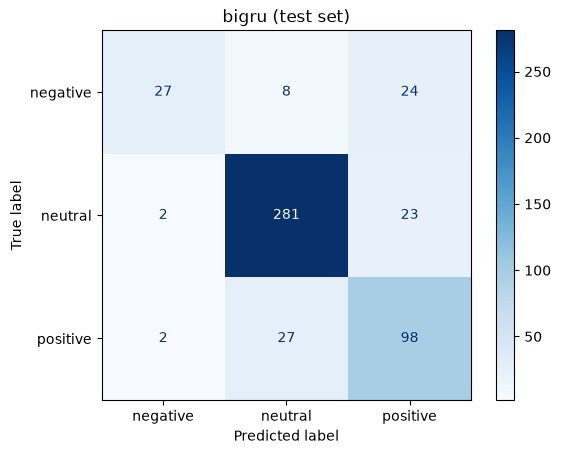

bigru on test: accuracy 0.8252 | Macro-F1 0.7414
              precision    recall  f1-score   support

    negative      0.871     0.458     0.600        59
     neutral      0.889     0.918     0.904       306
    positive      0.676     0.772     0.721       127

    accuracy                          0.825       492
   macro avg      0.812     0.716     0.741       492
weighted avg      0.832     0.825     0.820       492

bigru on test: accuracy 0.8252 | Macro-F1 0.7414
Total params: 542979
Saved model.


In [14]:
import sys, importlib
sys.path.append(str(PROJECT_ROOT))
import src.evaluate as ev
importlib.reload(ev)

test_df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "test.csv")
X_test = vectorizer(test_df["sentence_clean"].tolist()).numpy()

test_pred_ids = model.predict(X_test).argmax(axis=1)
test_pred = [LABELS[i] for i in test_pred_ids]
metrics = ev.evaluate(test_df["label"].tolist(), test_pred, "bigru", PROJECT_ROOT / "results")
print("bigru on test: accuracy", round(metrics["accuracy"], 4), "| Macro-F1", round(metrics["macro_f1"], 4))
print("Total params:", model.count_params())

model.save(PROJECT_ROOT / "models" / "bigru.keras")
print("Saved model.")